# Tech Challange - Wine
## Classificação da Qualidade de Vinhos com Machine Learning

### 1. INTRODUÇÃO
A avaliação da qualidade dos vinhos é uma etapa fundamental para a indústria vitivinícola, tradicionalmente realizada por especialistas por meio de análises sensoriais que consideram características como aroma, sabor, acidez e equilíbrio. Entretanto, esse processo pode apresentar subjetividade e demandar tempo e conhecimento especializado.
Neste projeto, irei aplicar técnicas de análise exploratória de dados, pré-processamento e aprendizado de máquina para construir e avaliar modelos capazes de classificar a qualidade de diferentes amostras de vinho.

### 2. Descrição dos dados utilizados
Será utilizado o Wine Quality Dataset, disponibilizado publicamente na plataforma Kaggle. O conjunto de dados contém informações físico-químicas de amostras de vinho, acompanhadas de uma avaliação de qualidade atribuída por especialistas.

|Variavel|Descrição|
|-----|------|
|fixed acidity|Acidez fixa do vinho|
|volatile acidity|Acidez volátil|
|citric acid|Concentração de ácido cítrico|
|residual sugar|Quantidade de açúcar residual|
|chlorides|Concentração de cloretos|
|free sulfur dioxide|Quantidade de dióxido de enxofre livre|
|total sulfur dioxide|Quantidade total de dióxido de enxofre|
|density|Densidade do vinho|
|pH|Nível de acidez ou alcalinidade|
|sulphates|Concentração de sulfatos|
|alcohol|Teor alcoólico|
|quality|Nota de qualidade atribuída por especialistas|

A variável quality será utilizada como referência para a construção da variável-alvo do modelo de classificação.

### 3. Objetivo do Projeto
O principal objetivo é desenvolver e comparar modelos de Machine Learning capazes de classificar a qualidade de um vinho com base em suas características físico-químicas.
Para isso, o problema será tratado como uma classificação binária, transformando a nota original de qualidade em duas categorias:
- Alta Qualidade (1): vinhos com nota maior ou igual a 7.
- Baixa/Média Qualidade (0): vinhos com nota inferior a 7.
Além da capacidade preditiva, busca-se compreender quais características físico-químicas apresentam maior relação com a qualidade dos vinhos e como esses resultados podem contribuir para decisões relacionadas ao processo produtivo.

### 4. Resultados Esperados
Ao final do projeto, espera-se obter um modelo capaz de identificar vinhos de alta qualidade a partir de suas propriedades físico-químicas, acompanhado de uma análise comparativa de desempenho e de uma interpretação dos principais fatores associados à classificação.
Mais do que alcançar bons indicadores preditivos, o projeto busca transformar dados em informações relevantes, demonstrando como técnicas de Machine Learning podem apoiar a compreensão da qualidade dos vinhos e contribuir para decisões mais fundamentadas na indústria vitivinícola.


### 5. Desenvolvimento Prático: Análise de Dados e Machine Learning
Para uso interno, estou criando um ambiente virtual para uso.
`python -m venv venv`
`venv\Script\activate`

### 6. Trabalhando os dados
#### 6.1. Importação das Bibliotecas
Para este desafio faremos uso das ferramentas Pandas, NumPy, MatPlot, Seaborn e Scikit-Learn.

In [767]:
# Instalação dos pacotes
# !pip install pandas numpy matplotlib seaborn scikit-learn

In [768]:
# Pandas
import pandas as pd

#NumPy
import numpy as np

#MatPlotLib
import matplotlib.pyplot as plt

#MissingNo
import missingno as msno

#SCIKit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import VotingClassifier

#Seaborn
import seaborn as sns

#### 6.2. Carregamento e Inspeção Inicial dos Dados

A base de dados utilizada será o Wine Quality Dataset, disponibilizado publicamente na plataforma Kaggle que se encontra em formato CSV e separado por `,`, conforme análise prévia do arquivo. Por ser uma base de dados única, utilizarei o `df` padrão como variável. Também já farei uma verificação prévia dos dados para validar a importação.

In [769]:
df = pd.read_csv('../data/WineQT.csv', sep=",")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [770]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [771]:
df.shape

(1143, 13)

In [772]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [773]:
df[df.duplicated()]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id


<Axes: >

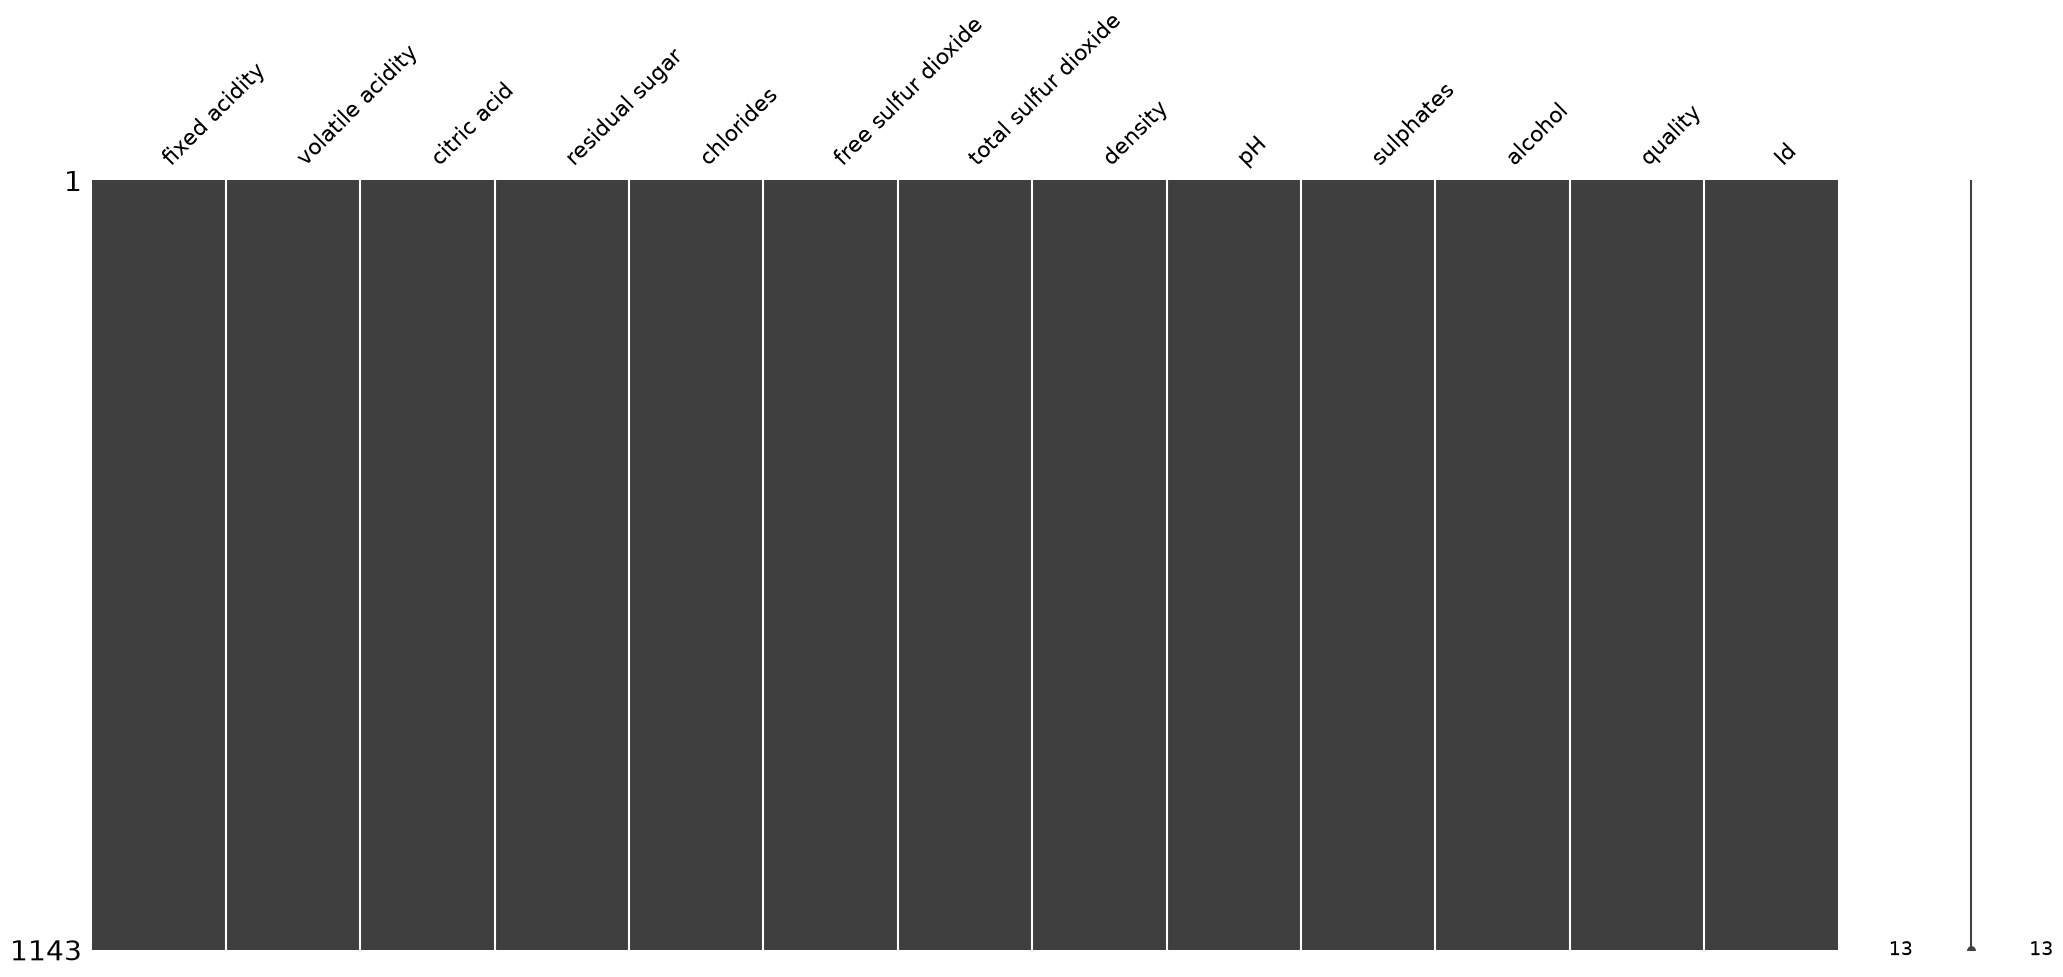

In [774]:
msno.matrix(df)

Realizei a validação dos seguintes requesitos para verificação da integridade dos dados.
- [x] Todas as colunas na importação foram corretamente alocadas
- [x] Todas as colunas foram reconhecidas com o formato correto a ser avaliado
- [x] Verificar o tamanho dos dados para uma melhor avalia
- [x] Se há dados nulos
- [x] Se há dados duplicados

#### 6.3 Análise Exploratória de Dados
Iniciarei olhando as estatisticas básicas da base de dados para iniciar uma analise sobre variação entre as métricas e iniciar a captura de insights para futuramente utilizar em minha análise.

In [775]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


A análise estatística descritiva identificou 1.143 amostras de vinho, sem valores ausentes nas variáveis apresentadas.
Como postura obvia, a coluna Id deverá ser excluida quando criarmos a predição pois representa apenas um identificador dos registros.

As notas de qualidade, que irão pautar toda nossa analise, variam entre 3 e 8, com média de 5,66 e mediana de 6. Isso indica que há uma concentração das avaliações em níveis intermediários. O que pode ser um problema por simplificarmos o sistema de classificação para binário, por possuir mais que 75% da base abaixo da nota de corte 7 que usaremos em nossa classificação.
Algumas características, especialmente açúcar residual, cloretos e dióxido de enxofre total, apresentam valores máximos significativamente superiores aos respectivos quartis. Isso deve ser investigado como possivel outliner que possa atrapalhar nossas analises.

Apesar de não conhecer muito sobre vinhos, o pH dos vinhos são geralmente ácidos o que condiz com os dados observados que variam entre 2,74 e 4,01, com média de 3,31. 
Percebi também que há 2 variáveis que falam sobre Dioxido de Enxofre, uma free e outra total. Portanto podemos analisar se há casos onde o livre supera o total, pois seria uma inconsistencia clara.

In [776]:
df[df["free sulfur dioxide"] > df["total sulfur dioxide"]]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id


Sanada esta dúvida, daqui para frente haverá a necessidade de investigar 3 grandes outliners:
1. Cloretos (chlorides) — máximo de 0,611
   A mediana deste item é de apenas 0,079, porém o máximo chega a aproximadamente 7,7 vezes esse valor.
2. Dióxido de enxofre total (total sulfur dioxide) — máximo de 289
   A mediana é de 37, enquanto o máximo chega a 289. Essa diferença merece atenção. Em pesquisa rápida na internet, o valor parece ser fisicamente plausível, mas relativamente elevado para determinados estilos de vinho. Vale verificar se corresponde a um registro legítimo.
3. Açúcar residual (residual sugar) — máximo de 15,5
   A mediana é de 2,2, enquanto o máximo chega a 15,5. A concentração alta deve ser vista, mas pode se tratar de um vinho tinto muito doce (sangue de boi ahaha)

##### 6.3.1 Investigação sobre o Cloretos
A mediana deste item é de apenas 0,079, porém o máximo chega a aproximadamente 7,7 vezes esse valor.
Primeiramente olharei os registros com maior valor neste capo, para analisar se as notas de qualidade deles também se assemelham entre si.

In [777]:
df.sort_values('chlorides', ascending=0).head(15)

## Descobri depois esta outra forma.
df.nlargest(
    15,
    "chlorides"
)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
182,7.7,0.410,0.76,1.8,0.611,8.0,45.0,0.99680,3.06,1.26,9.4,5,258
103,9.2,0.520,1.00,3.4,0.610,32.0,69.0,0.99960,2.74,2.00,9.4,4,151
75,7.8,0.410,0.68,1.7,0.467,18.0,69.0,0.99730,3.08,1.31,9.3,5,106
490,8.6,0.490,0.51,2.0,0.422,16.0,62.0,0.99790,3.03,1.17,9.0,5,692
538,7.8,0.480,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.1,6,754
973,8.7,0.780,0.51,1.7,0.415,12.0,66.0,0.99623,3.00,1.17,9.2,5,1370
975,8.7,0.780,0.51,1.7,0.415,12.0,66.0,0.99623,3.00,1.17,9.2,5,1372
738,8.5,0.460,0.59,1.4,0.414,16.0,45.0,0.99702,3.03,1.34,9.2,5,1051
934,9.1,0.760,0.68,1.7,0.414,18.0,64.0,0.99652,2.90,1.33,9.1,6,1319
890,8.6,0.635,0.68,1.8,0.403,19.0,56.0,0.99632,3.02,1.15,9.3,5,1260


Perante a qualidade de cada vinho, olharei agora a concentração deste campo para analisar se há relação entre a qualidade e a alta concentração neste dado.

In [778]:
df.groupby(
    df["quality"] >= 7
)["chlorides"].describe()

,count,mean,std,min,25%,50%,75%,max
quality,,,,,,,,
False,984.0,0.088908,0.049304,0.034,0.071,0.080,0.0910,0.611
True,159.0,0.074711,0.029154,0.012,0.062,0.073,0.0835,0.358


Incluirei em um gráfico para facilitar a visualização e comprovação de que a qualidade é ligada a esse campo. Se os valores elevados aparecerem predominantemente na classe de menor qualidade, isso poderá indicar que são informações úteis para o modelo.

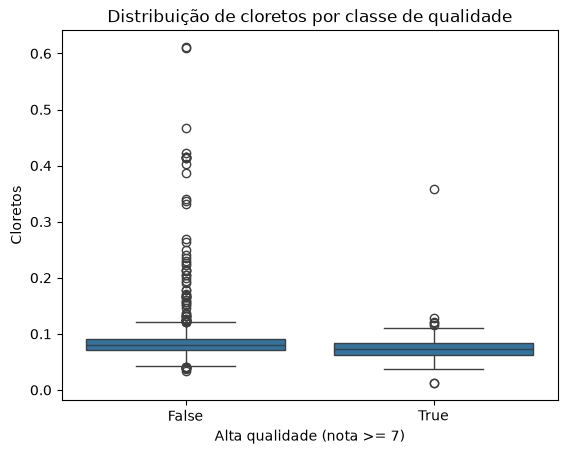

In [779]:
sns.boxplot(
    data=df,
    x=df["quality"] >= 7,
    y="chlorides"
)

plt.xlabel("Alta qualidade (nota >= 7)")
plt.ylabel("Cloretos")
plt.title("Distribuição de cloretos por classe de qualidade")
plt.show()

In [780]:
df.assign(
    alta_qualidade=df["quality"] >= 7,
    cloretos_elevados=df["chlorides"] > 0.120
).groupby("alta_qualidade")["cloretos_elevados"].agg(
    quantidade="sum",
    total="count",
    proporcao="mean"
)

,quantidade,total,proporcao
alta_qualidade,,,
False,63,984,0.064024
True,3,159,0.018868


A análise da distribuição de cloretos por classe de qualidade revelou que os vinhos classificados como de baixa/média qualidade apresentam maior dispersão e valores extremos mais elevados, chegando a 0,611 g/L.
Embora as medianas das duas classes sejam relativamente próximas, observa-se uma maior concentração visual de outliers superiores entre os vinhos de menor qualidade, sugerindo uma possível associação entre concentrações elevadas de cloretos e avaliações inferiores.
Dessa forma, manterei os outliers, uma vez que não foram identificadas evidências de inconsistências nos registros e esses valores podem conter informações relevantes para a classificação dos vinhos
Podemos posteriormente também testar o desempenho dos modelos com e sem os outliers, utilizando a mesma divisão de treino e teste, para avaliar se sua presença melhora ou prejudica a generalização.

##### 6.3.2 Dióxido de enxofre total (total sulfur dioxide) — máximo de 289
A mediana é de 37, enquanto o máximo chega a 289. Essa diferença merece atenção. 
Em pesquisa rápida na internet, o valor parece ser fisicamente plausível, mas relativamente elevado para determinados estilos de vinho. Vale verificar se corresponde a um registro legítimo.
Iniciarei novamente olhando os dados deste outliners para identificar se os valores extremos são isolados ou se existem diversas amostras com concentrações elevadas, se apresentam alguma característica incomum em outras variáveis e se estão associados a notas de qualidade específicas.

In [781]:
df.nlargest(
    15,
    "total sulfur dioxide"
)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
761,7.9,0.300,0.68,8.3,0.050,37.5,289.0,0.99316,3.01,0.51,12.3,7,1081
760,7.9,0.300,0.68,8.3,0.050,37.5,278.0,0.99316,3.01,0.51,12.3,7,1079
249,6.1,0.210,0.40,1.4,0.066,40.5,165.0,0.99120,3.25,0.59,11.9,6,354
485,9.8,0.980,0.32,2.3,0.078,35.0,152.0,0.99800,3.25,0.48,9.4,5,684
366,8.5,0.655,0.49,6.1,0.122,34.0,151.0,1.00100,3.31,1.14,9.3,5,515
421,6.6,0.390,0.49,1.7,0.070,23.0,149.0,0.99220,3.12,0.50,11.5,6,591
460,6.7,0.420,0.27,8.6,0.068,24.0,148.0,0.99480,3.16,0.57,11.3,6,649
452,9.6,0.880,0.28,2.4,0.086,30.0,147.0,0.99790,3.24,0.53,9.4,5,636
1066,7.7,0.540,0.26,1.9,0.089,23.0,147.0,0.99636,3.26,0.59,9.7,5,1493
453,9.5,0.885,0.27,2.3,0.084,31.0,145.0,0.99780,3.24,0.53,9.4,5,637


Observa-se que os maiores registros apresentam concentrações de 289 e 278, já o terceiro maior valor já cai para 165, uma diferença expressiva. Além disso, ambos receberam nota 7, enquanto os demais registros apresentados possuem notas 5 ou 6, isso contraria a hipótese de que concentrações elevadas de dióxido de enxofre total necessariamente estejam associadas à baixa qualidade.

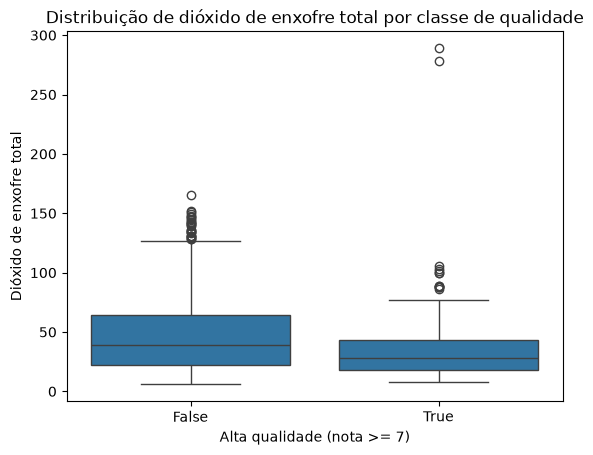

In [782]:
sns.boxplot(
    data=df,
    x=df["quality"] >= 7,
    y="total sulfur dioxide"
)

plt.xlabel("Alta qualidade (nota >= 7)")
plt.ylabel("Dióxido de enxofre total")
plt.title("Distribuição de dióxido de enxofre total por classe de qualidade")

plt.show()

In [783]:
df.assign(
    alta_qualidade=df["quality"] >= 7,
    so2_elevado=df["total sulfur dioxide"] > 121
).groupby("alta_qualidade")["so2_elevado"].agg(
    quantidade="sum",
    total="count",
    proporcao="mean"
)

,quantidade,total,proporcao
alta_qualidade,,,
False,38,984,0.038618
True,2,159,0.012579


Os resultados mostram um comportamento interessante que apesar de os dois maiores valores de dióxido de enxofre total pertencerem a vinhos de alta qualidade, concentrações elevadas são proporcionalmente mais frequentes nos vinhos de baixa/média qualidade.
A análise por classe revelou que 3,86% dos vinhos de baixa/média qualidade apresentam concentrações acima desse limite, enquanto apenas 1,26% dos vinhos de alta qualidade se encontram nessa condição. 
O gráfico também demonstrou medianas inferiores e menor dispersão na classe de alta qualidade, sugerindo uma possível associação entre concentrações menores de dióxido de enxofre total e melhores avaliações, mesmo com os outliners não seguindo a condição.
Manterei os outliers nesta etapa, pois não foram identificadas evidências suficientes de erros ou inconsistências que justifiquem sua exclusão. A influência desses registros poderá ser reavaliada durante a modelagem.

##### 6.3.3 Açúcar residual (residual sugar) — máximo de 15,5
A mediana é de 2,2, enquanto o máximo chega a 15,5. A concentração alta deve ser vista, mas pode se tratar de um vinho tinto muito doce (sangue de boi ahaha)

In [784]:
df.nlargest(
    15,
    "residual sugar"
)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
339,10.6,0.280,0.39,15.5,0.069,6.0,23.0,1.00260,3.12,0.66,9.2,5,480
1022,10.2,0.540,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,6,1434
1051,9.9,0.500,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,5,1474
1053,9.9,0.500,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,5,1476
230,10.0,0.490,0.20,11.0,0.071,13.0,50.0,1.00150,3.16,0.69,9.2,6,324
231,10.0,0.490,0.20,11.0,0.071,13.0,50.0,1.00150,3.16,0.69,9.2,6,325
644,9.1,0.280,0.46,9.0,0.114,3.0,9.0,0.99901,3.18,0.60,10.9,6,911
648,6.8,0.410,0.31,8.8,0.084,26.0,45.0,0.99824,3.38,0.64,10.1,6,917
460,6.7,0.420,0.27,8.6,0.068,24.0,148.0,0.99480,3.16,0.57,11.3,6,649
348,6.5,0.390,0.23,8.3,0.051,28.0,91.0,0.99520,3.44,0.55,12.1,6,494


Entre os maiores registros, temos vinhos de média qualidade em quase todos esses maior concentração de açucar residual. Isso sugere uma possível associação entre concentrações muito elevadas de açúcar residual e avaliações inferiores. Entretanto, precisamos comparar as proporções entre as classes antes de concluir.
Neste caso achei um caso interessante, existem alguns dados que são exatamente iguais, apenas com o id diferente, conforme podemos observar entre os registros: (1051 e 1053), (230 e 231) e (275 e 278).

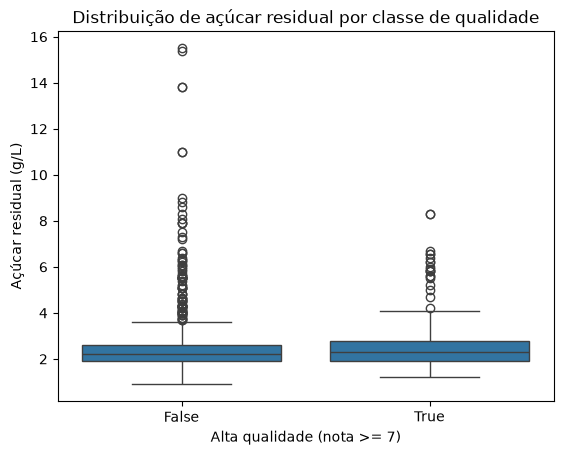

In [785]:
sns.boxplot(
    data=df,
    x=df["quality"] >= 7,
    y="residual sugar"
)

plt.xlabel("Alta qualidade (nota >= 7)")
plt.ylabel("Açúcar residual (g/L)")
plt.title("Distribuição de açúcar residual por classe de qualidade")

plt.show()

In [786]:
df.assign(
    alta_qualidade=df["quality"] >= 7,
    acucar_elevado=df["residual sugar"] > 3.65
).groupby("alta_qualidade")["acucar_elevado"].agg(
    quantidade="sum",
    total="count",
    proporcao="mean"
)

,quantidade,total,proporcao
alta_qualidade,,,
False,85,984,0.086382
True,25,159,0.157233


Os registros com maiores concentrações pertencem predominantemente à classe de baixa/média qualidade. Observou-se também que as amostras com concentrações mais elevadas de açúcar apresentam, em geral, densidades superiores e teores alcoólicos relativamente baixos, comportamento compatível com as propriedades físico-químicas dos vinhos.
Foram identificados ainda possíveis registros duplicados, que deverão ser investigados separadamente durante a etapa de tratamento dos dados.
Manterei os outliers de açúcar residual, uma vez que os valores são fisicamente plausíveis e podem conter informações relevantes para a classificação. A decisão será reavaliada após a análise da distribuição por classe de qualidade.

In [787]:
df_analise = df.copy()

df_analise["faixa_acucar"] = pd.cut(
    df_analise["residual sugar"],
    bins=[0, 2, 3.65, 6, 10, float("inf")],
    labels=[
        "Até 2",
        "2 a 3,65",
        "3,65 a 6",
        "6 a 10",
        "Acima de 10"
    ]
)

df_analise.groupby(
    "faixa_acucar",
    observed=True
).agg(
    quantidade=("quality", "size"),
    qualidade_media=("quality", "mean"),
    proporcao_alta_qualidade=(
        "quality",
        lambda x: (x >= 7).mean()
    )
)

,quantidade,qualidade_media,proporcao_alta_qualidade
faixa_acucar,,,
Até 2,439,5.624146,0.116173
"2 a 3,65",594,5.668350,0.139731
"3,65 a 6",76,5.723684,0.223684
6 a 10,28,5.785714,0.285714
Acima de 10,6,5.500000,0.000000


##### 6.3.4 Análise Gráfica dos Dados
Vamos analisar uma contagem por qualidade do vinho para verificar possiveis concentrações.

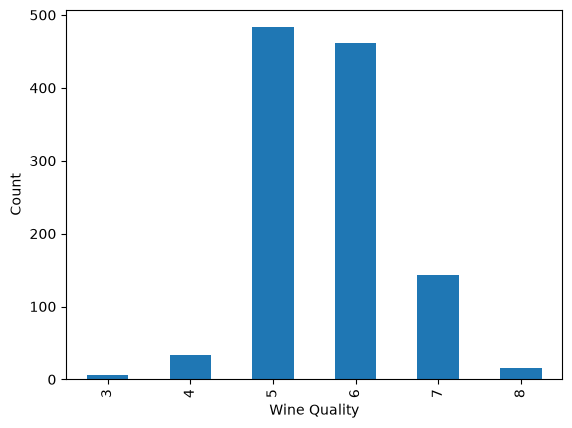

In [788]:
df['quality'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Wine Quality')
plt.ylabel('Count')
plt.show()

Há uma evidente concentração entre vinhos de qualidade 5, 6 e 7 e não temos nenhum vinho de qualidade muito baixa ou muito alta nas analises.
Analisarei agora a quantidade média de cada um dos campos para cada qualidade com o intuito de iniciar uma analise de algum padrão evidente entre as qualidades.

In [789]:
# Calculando a média dos volumes para cada uma das qualidades.
df.groupby('quality').mean()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
quality,,,,,,,,,,,,
3,8.450000,0.897500,0.211667,2.666667,0.105333,8.166667,24.500000,0.997682,3.361667,0.550000,9.691667,1121.166667
4,7.809091,0.700000,0.165758,2.566667,0.094788,14.848485,40.606061,0.996669,3.391212,0.637879,10.260606,692.848485
5,8.161077,0.585280,0.240124,2.540476,0.091770,16.612836,55.299172,0.997073,3.302091,0.613375,9.902277,753.925466
6,8.317749,0.504957,0.263680,2.444805,0.085281,15.215368,39.941558,0.996610,3.323788,0.676537,10.655339,854.625541
7,8.851049,0.393671,0.386573,2.760140,0.075217,14.538462,37.489510,0.996071,3.287133,0.743566,11.482634,830.349650
8,8.806250,0.410000,0.432500,2.643750,0.070187,11.062500,29.375000,0.995553,3.240625,0.766250,11.937500,797.875000


Olhando para os dados acima podemos observar alguns padrões evidentes entre a correção da qualidade com cada parâmeto.

Variável|Comportamento observado|Possível interpretação
|------|------------------------|----------------------
alcohol|Aumenta|Vinhos de maior qualidade apresentam, em média, maior teor alcoólico.
volatile acidity|Diminui|Menor acidez volátil está associada a melhores avaliações.
citric acid|Aumenta|Vinhos de maior qualidade apresentam maior concentração média de ácido cítrico.
sulphates|Aumenta|Maiores concentrações médias estão associadas a notas superiores.
chlorides|Diminui|Concentrações menores estão associadas a vinhos mais bem avaliados.
density|Diminui|Vinhos com melhores avaliações tendem a apresentar densidades menores, apesar da cariação ser bem pequena.
total sulfur dioxide|Oscila|Não apresenta uma tendência clara.
residual sugar|Oscila|Não apresenta uma tendência clara.
fixed acidity|Oscila|Apresenta pequenas variações, não apresenta uma tendência clara.
pH|Oscila|Não apresenta uma tendência clara.
free sulfur dioxide|Oscila|Não apresenta uma tendência clara.


Analisarei agora a distribuição do teor alcólico para cada uma das qualidades.

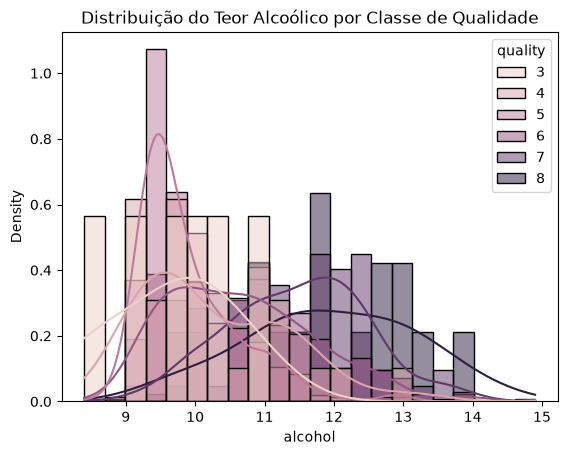

In [790]:
sns.histplot(
    data=df,
    x='alcohol',
    hue='quality',
    stat='density',
    common_norm=False,
    kde=True
)

plt.title('Distribuição do Teor Alcoólico por Classe de Qualidade')
plt.show()

A análise da distribuição do teor alcoólico por classe de qualidade indica uma associação entre essa característica e a avaliação dos vinhos. Amostras com notas mais elevadas (7 e 8) apresentam maior concentração em faixas superiores de teor alcoólico, enquanto as notas intermediárias (5 e 6) predominam em faixas inferiores. Entretanto, a sobreposição entre as distribuições demonstra que o teor alcoólico, isoladamente, não é suficiente para distinguir as classes de qualidade.

Agora observaremos se os pontos que observamos como possiveis padrões se as medianas acompanham as tendências das médias, se existe muita sobreposição entre notas e se valores extremos estão influenciando os resultados.

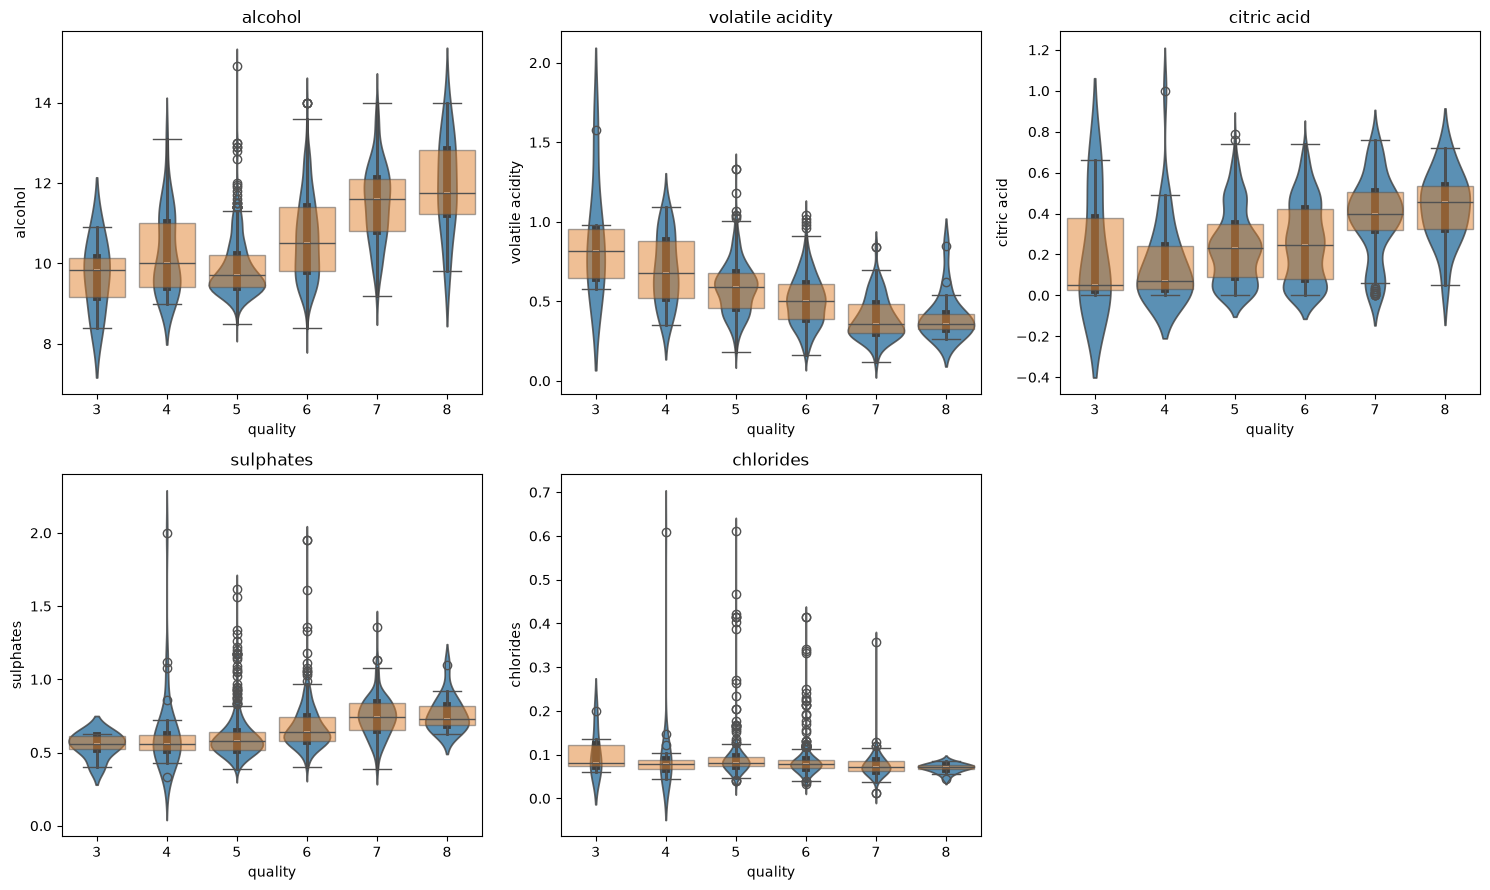

In [791]:
variaveis = [
    'alcohol',
    'volatile acidity',
    'citric acid',
    'sulphates',
    'chlorides'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, var in zip(axes.flat, variaveis):
    sns.violinplot(data=df, x='quality', y=var, ax=ax, alpha=0.8)
    sns.boxplot(data=df, x='quality', y=var, ax=ax, boxprops={'alpha': 0.5})
    ax.set_title(var)

for ax in axes.flat[len(variaveis):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

A análise do ViolinPlot junto ao BoxPlot confirmou as principais tendências identificadas anteriormente nas médias das características físico-químicas. O teor alcoólico apresentou aumento das medianas nos vinhos de maior qualidade, enquanto a acidez volátil demonstrou comportamento inverso. O ácido cítrico e os sulfatos também apresentaram associação positiva com as avaliações. Por outro lado, os cloretos demonstraram diferenças menos expressivas entre as medianas e maior presença de valores extremos. Apesar dessas tendências, a sobreposição entre as distribuições indica que nenhuma característica isolada é suficiente para determinar a qualidade dos vinhos.

<Axes: xlabel='quality_bin', ylabel='count'>

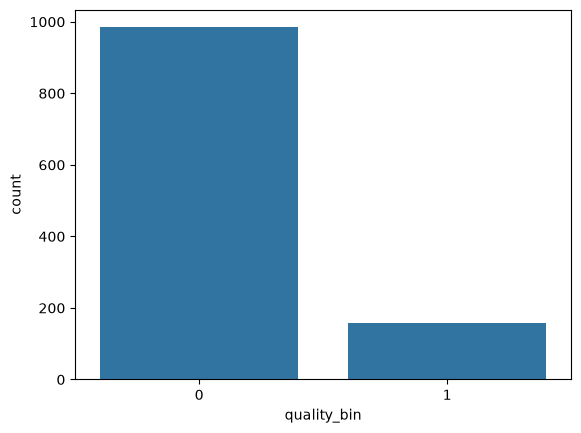

In [792]:
# Para melhorar a visualização dos gráfico farei aqui um passo que posteriormente será novamente estanciado para analise.
df['quality_bin'] = (df['quality'] >= 7).astype(int)
sns.countplot(x="quality_bin", data=df)


Aqui verificamos claramente que temos uma disparidade grande entre os exemplos de cada uma das classificações das qualidades. Haverá posteriormente a avaliação dos modelos realizando mecanismos de equalização destas bases para que tenhamos modelos preditivos mais potentes ou não.

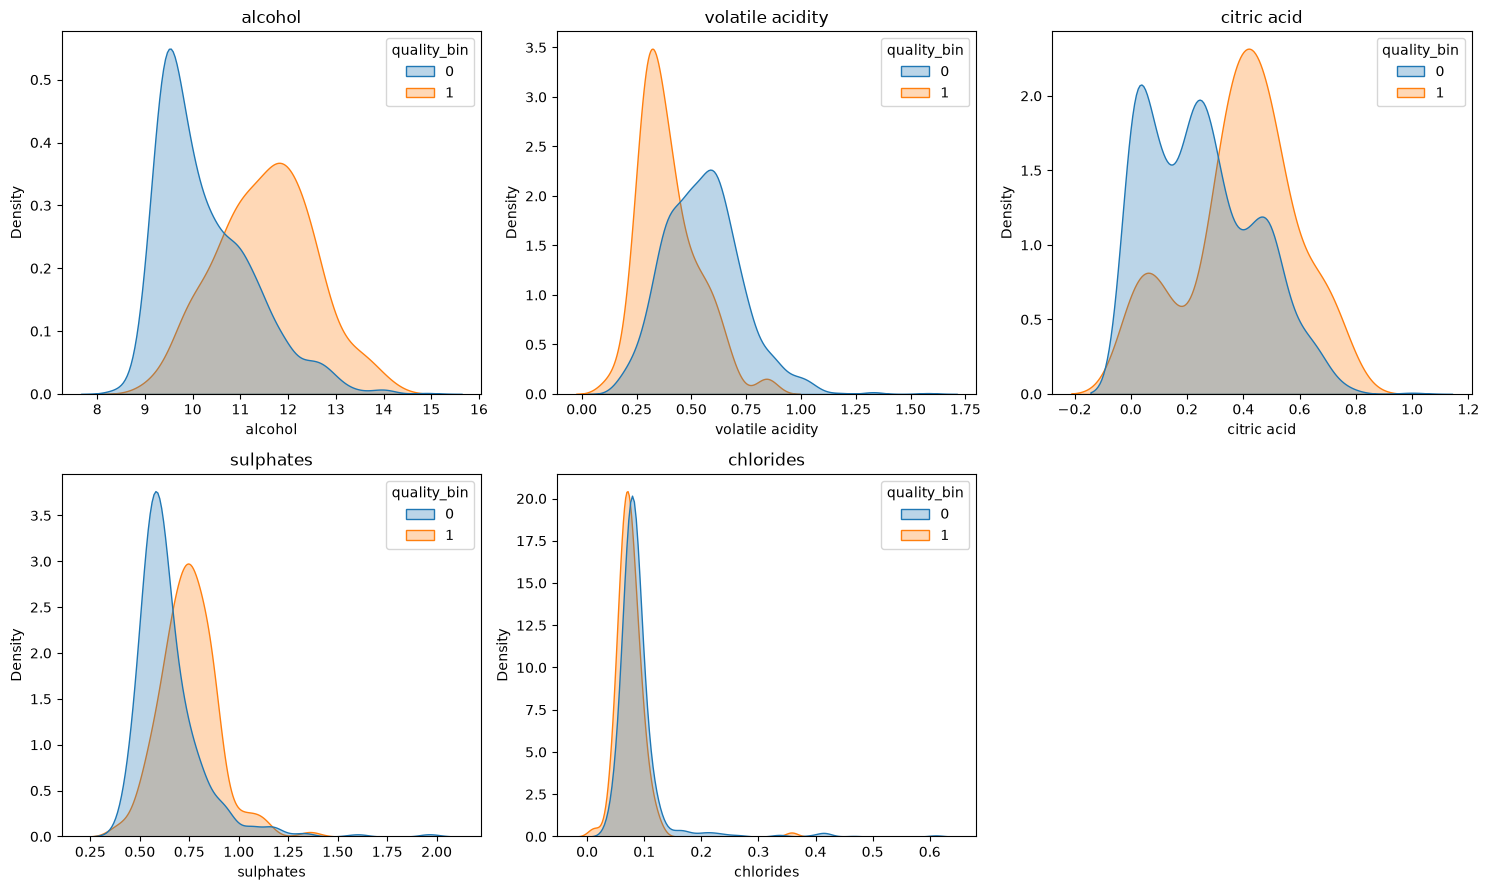

In [793]:

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, var in zip(axes.flat, variaveis):
    sns.kdeplot(
        data=df,
        x=var,
        hue='quality_bin',
        common_norm=False,
        fill=True,
        alpha=0.3,
        ax=ax
    )
    ax.set_title(var)

for ax in axes.flat[len(variaveis):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

A análise das distribuições de densidade reforçou as tendências identificadas nas médias e nos boxplots. Os vinhos de maior qualidade apresentam distribuições deslocadas para teores alcoólicos e concentrações de ácido cítrico mais elevados, enquanto a acidez volátil tende a assumir valores menores. Os sulfatos também apresentam associação positiva, embora com diferenças menos expressivas. Por outro lado, os cloretos apresentam elevada sobreposição entre as notas, indicando menor capacidade aparente de discriminação individual. De maneira geral, os resultados sugerem que a combinação de múltiplas características será necessária para uma classificação mais eficiente.

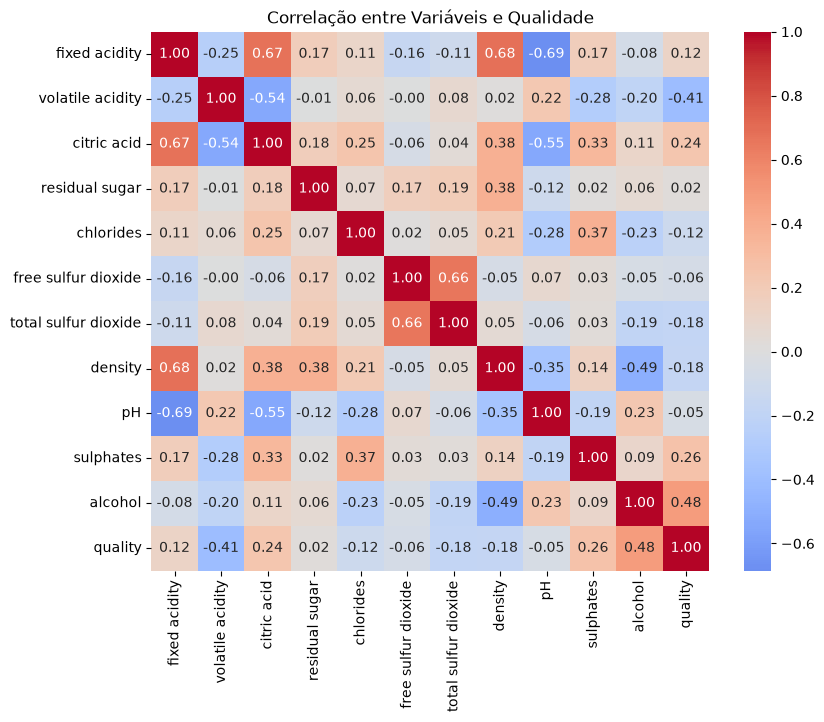

In [794]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    df.drop(['Id', 'quality_bin'], axis=1).corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlação entre Variáveis e Qualidade')
plt.show()

Podemos destacar algumas correções de grande influencia abaixo demosntradas.

Variáveis|Correlação
|-----|-------|
fixed acidity × pH|-0,69
fixed acidity × density|0,68
fixed acidity × citric acid|0,67
free sulfur dioxide × total sulfur dioxide (será desconsiderado pela relação óbvia) |0,66
citric acid × pH|-0,55
volatile acidity × citric acid|-0,54
density × alcohol|-0,49


A análise da matriz de correlação identificou o teor alcoólico (+0,48) e a acidez volátil (-0,41) como as características com associações lineares mais expressivas com a qualidade dos vinhos, confirmando os comportamentos observados nas análises anteriores. Sulfatos e ácido cítrico apresentaram associações positivas mais fracas, enquanto outras variáveis demonstraram relações pouco expressivas. Também foram identificadas correlações relevantes entre características físico-químicas, especialmente entre acidez fixa, pH, densidade e ácido cítrico, indicando a presença de informações compartilhadas entre os atributos. Essas relações deverão ser consideradas na interpretação dos modelos, sem justificar, isoladamente, a exclusão de variáveis.

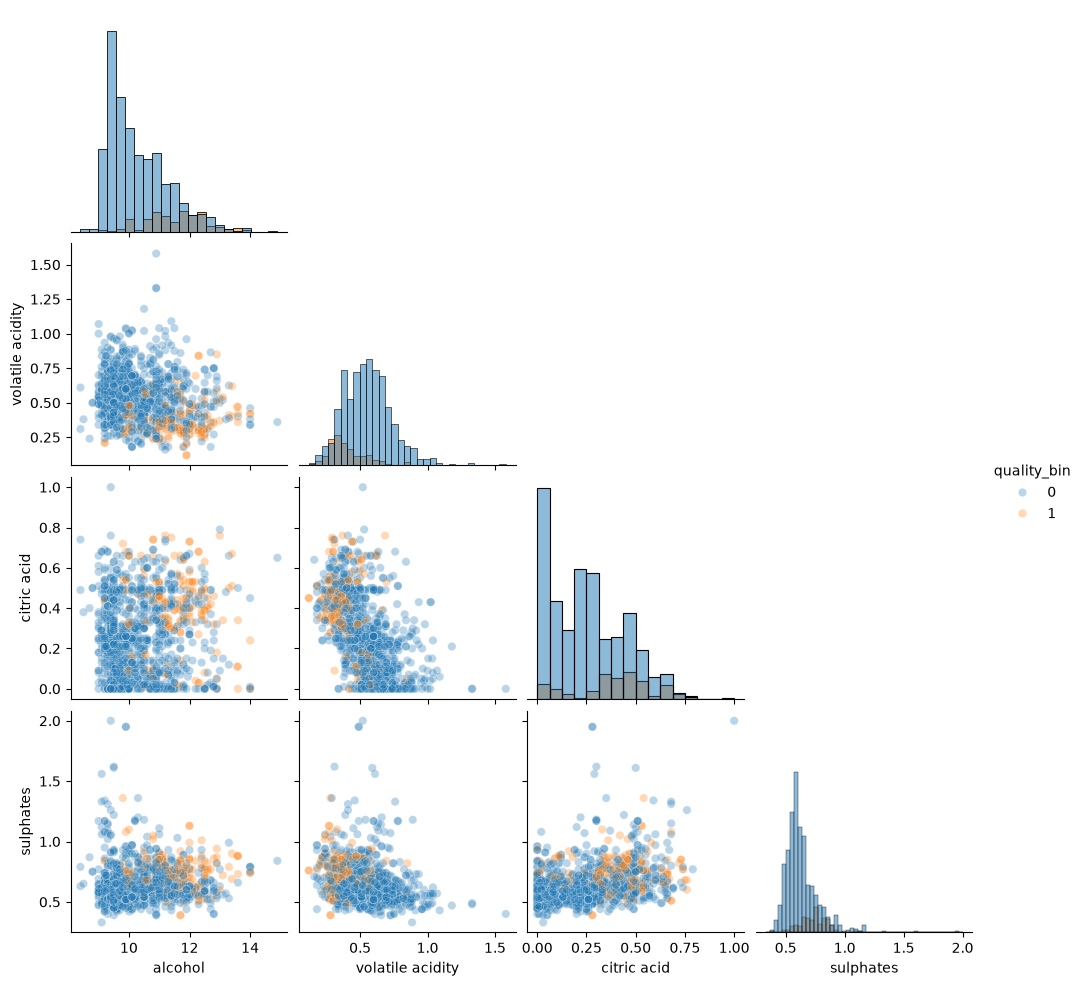

In [795]:
#Visualize pairwise relationships across all features using a pairplot

sns.pairplot(
    df,
    vars=['alcohol', 'volatile acidity', 'citric acid', 'sulphates'],
    hue='quality_bin',
    corner=True,
    diag_kind='hist',
    plot_kws={'alpha': 0.3}
)

plt.show()

A análise conjunta das características físico-químicas, segmentada pela classificação binária, revelou padrões relevantes para a identificação de vinhos de alta qualidade. Observou-se maior presença relativa de amostras da classe 1 em regiões com teor alcoólico elevado, menor acidez volátil e maiores concentrações de ácido cítrico e sulfatos. Entretanto, a elevada sobreposição entre as classes demonstra que nenhuma combinação de duas características analisadas permite uma separação visual completa. Além disso, a predominância da classe 0 evidencia o desbalanceamento do dataset, aspecto que deverá ser considerado na construção e avaliação dos modelos de classificação.

#### 6.4. Pré-processamento e Preparação dos Dados
Com as informações recolhidas nas etapas anteriores, como trabalho dos dados teremos que realizar apenas a retirada do campo de `id` da base, a criação da coluna binária de qualidade e a separação das bases de treino e de teste.

In [796]:
# Retirando da base o campo "id", estou retirando o quality_bin para deixar documentada a inclusão do mesmo na preparação dos dados abaixo
df.drop(['Id'], axis=1, inplace=True)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_bin
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [797]:
# Criação da coluna binária e retirada da base de qualidade (1 = "boa qualidade" e 0 = "baixa qualidade")
df['quality_bin'] = (df['quality'] >= 7).astype(int)
df.drop('quality', axis=1, inplace=True)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality_bin
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0


In [798]:
# Separação das bases de x e y
x = df.drop('quality_bin', axis=1)
y = df['quality_bin']

In [799]:
# Separação das bases de treino e de teste

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Aqui já temos os dados separados para a utilização nos modelos que iremos trabalhar abaixo.

#### 6.5. Desenvolvimento e Treinamento dos Modelos
Defini que iremos trabalhar 4 modelos diferentes comparando-os para que possamos chegar em um melhor modelo de predição para o exercicio. Para isso, por se tratar de uma definição binária entre bom e ruim em qualidade optarei pela execução dos 4 modelos abaixo com suas respectivas caracteristicas. Criarei uma variável onde armazenaremos os dados para uma visualização posterior do melhor modelo que podemos utilizar.

| Modelo | Por que testar? | Principal cuidado | Usar base padronizada? |
|---|---|---|---|
| **KNN** | Explora a hipótese de que vinhos com características físico-químicas semelhantes possuem classificações semelhantes. | É sensível ao número de vizinhos, aos outliers e ao desbalanceamento das classes. | **Sim** |
| **Regressão Logística** | É uma boa referência inicial e permite interpretar como as características contribuem para a classificação. | Pode ter limitações para capturar relações não lineares; variáveis correlacionadas dificultam a interpretação dos coeficientes. | **Sim** |
| **Random Forest** | Captura relações não lineares e interações entre as características. | Pode apresentar sobreajuste e favorecer a classe majoritária. Controle a complexidade das árvores e avalie a classe de alta qualidade. | **Não** |
| **Gaussian Naive Bayes** | É simples, rápido e permite avaliar uma abordagem probabilística para os atributos numéricos. | Supõe independência entre os atributos e distribuição normal de cada característica dentro de cada classe. Padronizar não torna as distribuições normais. | **Não** |


- Feature Scaling: 
Trabalharei os dados com Feature Scaling para que normalizemos os dados de forma a maximizar os dados para a aplicação dos modelos que forem mais performáticos com o mesmo como Regressão Logistica e KNN.

In [800]:
resultados_modelos = []

##### 6.5.1 Modelo KNN 
Para este modelo utilizaremos o modelo escalonado para melhorar a performance do modelo. Porém temos o parámetro de `n_neighbor" que temos que determinar um número ideial. Para isso, criaremos um looping com um range de 1 a 20 para determinarmos a melhor escala possivel e posteriormente analisaremos em gráfico a taxa de erros.

In [801]:
pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier()),
    
])

parametros = {
    'knn__n_neighbors': range(1, 21),
    'knn__weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(
    pipeline_knn,
    param_grid=parametros,
    cv=5,
    scoring='f1'
)

grid_knn.fit(X_train, y_train)

print("Melhores parâmetros:", grid_knn.best_params_)
print("Melhor F1 médio:", grid_knn.best_score_)

melhor_modelo_knn = grid_knn.best_estimator_

y_pred_knn = melhor_modelo_knn.predict(X_test)

print(classification_report(y_test, y_pred_knn))

resultados_modelos.append({
        'Modelo': 'KNN',
        'F1 CV': grid_knn.best_score_,
        'Melhores Parâmetros': grid_knn.best_params_
    })

Melhores parâmetros: {'knn__n_neighbors': 11, 'knn__weights': 'distance'}
Melhor F1 médio: 0.5880867743284643
              precision    recall  f1-score   support

           0       0.92      0.97      0.95       197
           1       0.73      0.50      0.59        32

    accuracy                           0.90       229
   macro avg       0.82      0.73      0.77       229
weighted avg       0.90      0.90      0.90       229



##### 6.5.2 Regressão Logística


In [802]:
pipeline_log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))

])

parametros = {
            'logistic__C': [0.01, 0.1, 1, 10, 100],
            'logistic__class_weight': [None, 'balanced']
        }

grid_log_reg = GridSearchCV(
    pipeline_log_reg,
    param_grid=parametros,
    cv=5,
    scoring='f1'
)

grid_log_reg.fit(X_train, y_train)

print("Melhores parâmetros:", grid_log_reg.best_params_)
print("Melhor F1 médio:", grid_log_reg.best_score_)

melhor_modelo_log_reg = grid_log_reg.best_estimator_

y_pred_log_reg = melhor_modelo_log_reg.predict(X_test)

print(classification_report(y_test, y_pred_log_reg))

resultados_modelos.append({
        'Modelo': 'Regressão Logistica',
        'F1 CV': grid_log_reg.best_score_,
        'Melhores Parâmetros': grid_log_reg.best_params_
    })

Melhores parâmetros: {'logistic__C': 10, 'logistic__class_weight': 'balanced'}
Melhor F1 médio: 0.5304746297687475
              precision    recall  f1-score   support

           0       0.94      0.82      0.87       197
           1       0.37      0.66      0.47        32

    accuracy                           0.79       229
   macro avg       0.65      0.74      0.67       229
weighted avg       0.86      0.79      0.82       229




##### 6.5.3 Random Forest


In [803]:
pipeline_rand_forest = Pipeline([
      ('random', RandomForestClassifier(
          random_state=42
      ))
  ])

parametros = {
            'random__n_estimators': [100, 200],
            'random__max_depth': [None, 5, 10],
            'random__min_samples_leaf': [1, 3, 5],
            'random__class_weight': [None, 'balanced']
        }

grid_rand_forest = GridSearchCV(
    pipeline_rand_forest,
    param_grid=parametros,
    cv=5,
    scoring='f1'
)

grid_rand_forest.fit(X_train, y_train)

print("Melhores parâmetros:", grid_rand_forest.best_params_)
print("Melhor F1 médio:", grid_rand_forest.best_score_)

melhor_modelo_rand_forest = grid_rand_forest.best_estimator_

y_pred_rand_forest = melhor_modelo_rand_forest.predict(X_test)

print(classification_report(y_test, y_pred_rand_forest))

resultados_modelos.append({
        'Modelo': 'Random Forest',
        'F1 CV': grid_rand_forest.best_score_,
        'Melhores Parâmetros': grid_rand_forest.best_params_
    })

Melhores parâmetros: {'random__class_weight': 'balanced', 'random__max_depth': 10, 'random__min_samples_leaf': 1, 'random__n_estimators': 200}
Melhor F1 médio: 0.6347659599928202
              precision    recall  f1-score   support

           0       0.95      0.92      0.93       197
           1       0.58      0.69      0.63        32

    accuracy                           0.89       229
   macro avg       0.76      0.80      0.78       229
weighted avg       0.90      0.89      0.89       229




##### 6.5.2 Gaussian Naive Bayes

In [804]:
pipeline_bayes = Pipeline([
      ('scaler', StandardScaler()),
      ('bayes', GaussianNB())
  ])

parametros = {
            'bayes__var_smoothing': np.logspace(-11, -7, 9)
        }

grid_bayes = GridSearchCV(
    pipeline_bayes,
    param_grid=parametros,
    cv=5,
    scoring='f1'
)

grid_bayes.fit(X_train, y_train)

print("Melhores parâmetros:", grid_bayes.best_params_)
print("Melhor F1 médio:", grid_bayes.best_score_)

melhor_modelo_bayes = grid_bayes.best_estimator_

y_pred_bayes = melhor_modelo_bayes.predict(X_test)

print(classification_report(y_test, y_pred_bayes))

Melhores parâmetros: {'bayes__var_smoothing': np.float64(1e-11)}
Melhor F1 médio: 0.537303274682307
              precision    recall  f1-score   support

           0       0.93      0.88      0.91       197
           1       0.45      0.59      0.51        32

    accuracy                           0.84       229
   macro avg       0.69      0.74      0.71       229
weighted avg       0.86      0.84      0.85       229




#### 6.6. Avaliação e Comparação dos Modelos


In [805]:
df_cv = pd.DataFrame(resultados_modelos)

display(
    df_cv.sort_values(
        by='F1 CV',
        ascending=False
    )
)

,Modelo,F1 CV,Melhores Parâmetros
2,Random Forest,0.634766,"{'random__class_weight': 'balanced', 'random__..."
0,KNN,0.588087,"{'knn__n_neighbors': 11, 'knn__weights': 'dist..."
1,Regressão Logistica,0.530475,"{'logistic__C': 10, 'logistic__class_weight': ..."


In [806]:
resultados_teste = []
melhores_modelos = {
    'KNN': grid_knn.best_estimator_,
    'Regressão Logística': grid_log_reg.best_estimator_,
    'Random Forest': grid_rand_forest.best_estimator_,
    'Gaussian Naive Bayes': grid_bayes.best_estimator_
}

for nome, modelo in melhores_modelos.items():

    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]

    resultados_teste.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

df_resultados = pd.DataFrame(resultados_teste)

display(
    df_resultados.sort_values(
        by='F1-score',
        ascending=False
    ).round(4)
)

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC
2,Random Forest,0.8865,0.5789,0.6875,0.6286,0.9086
0,KNN,0.9039,0.7273,0.5000,0.5926,0.8525
3,Gaussian Naive Bayes,0.8428,0.4524,0.5938,0.5135,0.8104
1,Regressão Logística,0.7948,0.3684,0.6562,0.4719,0.8503


A comparação dos quatro algoritmos demonstrou que o Random Forest apresentou o melhor equilíbrio entre precisão e recall. Embora o KNN tenha obtido a maior acurácia e precisão, identificou apenas 50% dos vinhos de alta qualidade. O Gaussian Naive Bayes apresentou desempenho intermediário, enquanto a Regressão Logística obteve o menor F1-score. Considerando o desbalanceamento das classes e o objetivo de identificar vinhos de alta qualidade, o Random Forest se destacou como a alternativa mais promissora entre os modelos avaliados.
Para avaliarmos melhor criaremos uma Matriz de Confusão dos 4 modelos para verificarmos falsos positivos e falsos negativos e explicar os resultados de forma mais intuitiva.

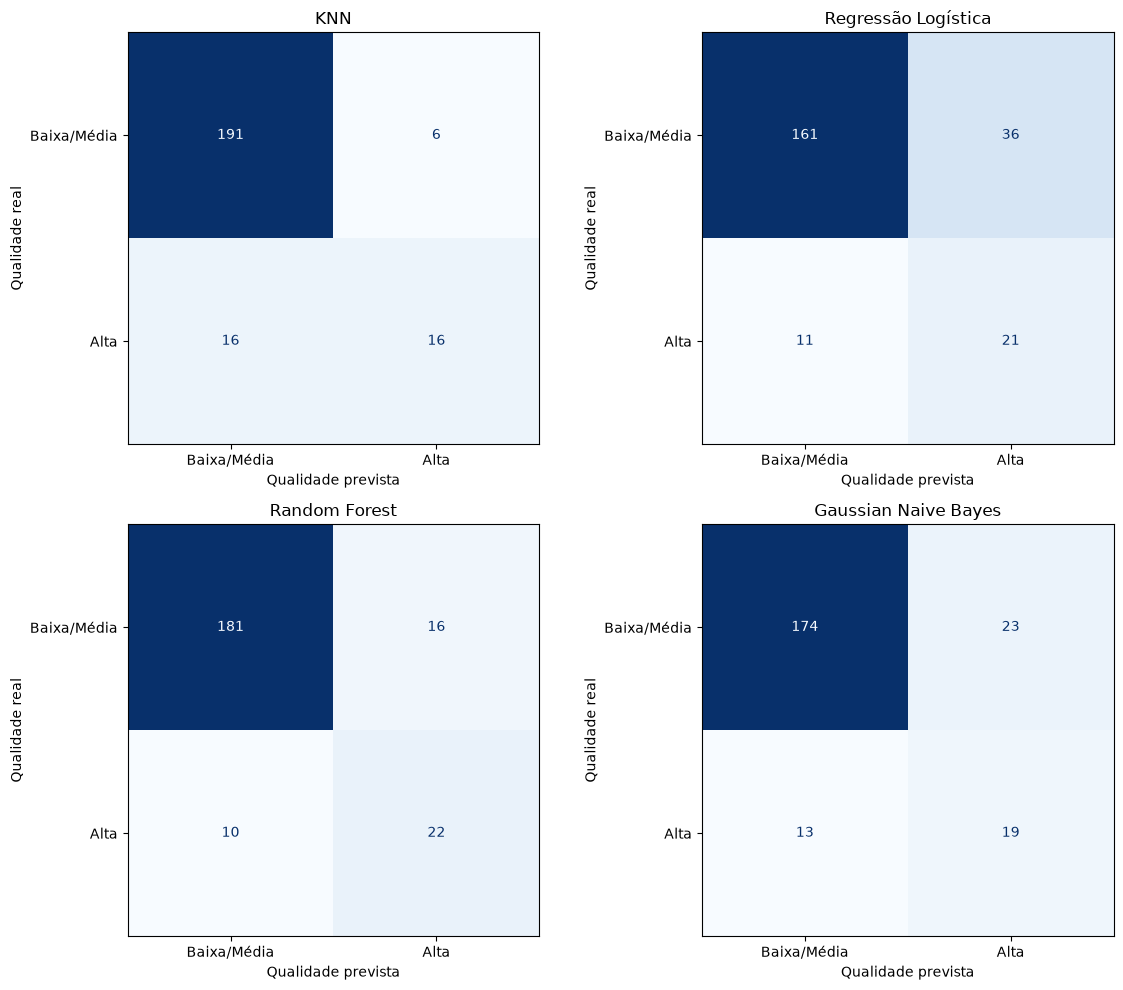

In [807]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (nome, modelo) in zip(axes.flat, melhores_modelos.items()):

    y_pred = modelo.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Baixa/Média', 'Alta']
    ).plot(
        ax=ax,
        cmap='Blues',
        colorbar=False,
        values_format='d'
    )

    ax.set_title(nome)
    ax.set_xlabel('Qualidade prevista')
    ax.set_ylabel('Qualidade real')

plt.tight_layout()
plt.show()

A análise das matrizes de confusão reforça a escolha do Random Forest como principal candidato. O modelo identificou corretamente 22 dos 32 vinhos de alta qualidade, apresentando 10 falsos negativos e 16 falsos positivos. Embora o KNN tenha alcançado maior número de acertos totais, deixou de identificar metade dos vinhos de alta qualidade. A Regressão Logística apresentou recall próximo ao Random Forest, porém com quantidade significativamente maior de falsos positivos. Dessa forma, considerando o objetivo de identificar vinhos de alta qualidade e o desbalanceamento das classes, o Random Forest apresentou o desempenho mais equilibrado. Já prevejo aqui que possivelmente o tamanho da nossa base de dados seja um das grandes barreiras que estamos enfrentando para uma maior assertividade dos modelos.

Acho importante que analisemos também as features mais importantes, 

In [808]:
modelo_rf = grid_rand_forest.best_estimator_
rf = modelo_rf.named_steps['random']

df_importancia = pd.DataFrame({
    'Variável': X_train.columns,
    'Importância': rf.feature_importances_
}).sort_values(
    by='Importância',
    ascending=False
).round(2)

display(df_importancia)

,Variável,Importância
10,alcohol,0.23
9,sulphates,0.14
2,citric acid,0.14
1,volatile acidity,0.11
7,density,0.07
6,total sulfur dioxide,0.07
0,fixed acidity,0.06
4,chlorides,0.05
8,pH,0.05
3,residual sugar,0.05


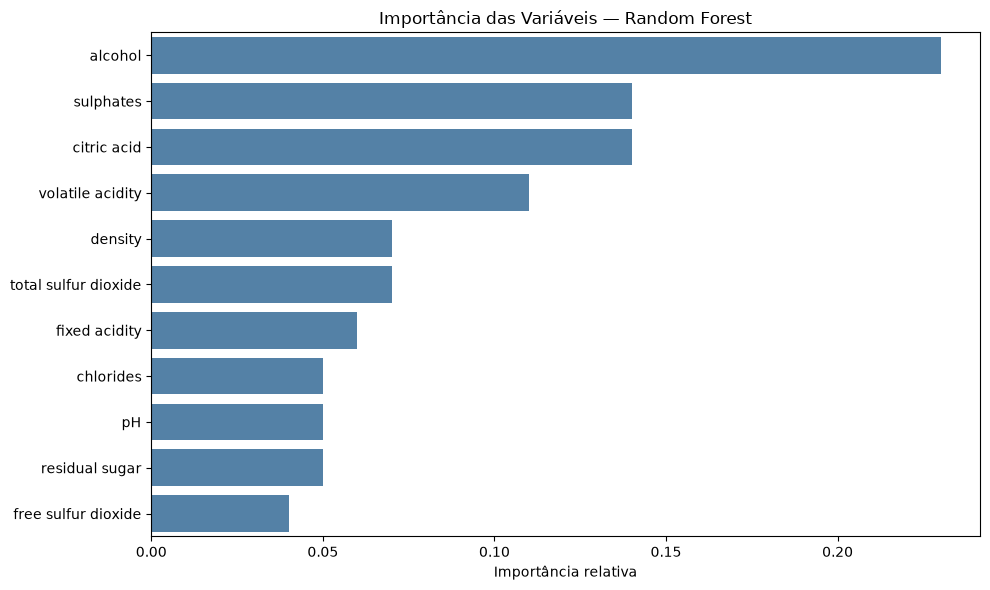

In [809]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_importancia,
    x='Importância',
    y='Variável',
    color='steelblue'
)

plt.title('Importância das Variáveis — Random Forest')
plt.xlabel('Importância relativa')
plt.ylabel('')
plt.tight_layout()
plt.show()

A análise de importância das variáveis do Random Forest demonstrou que o teor alcoólico foi a característica mais relevante para a classificação da qualidade dos vinhos, seguido pelos sulfatos, ácido cítrico e acidez volátil. Juntas, essas quatro variáveis representaram aproximadamente 62% da importância total atribuída pelo modelo. Os resultados são consistentes com a análise exploratória, que identificou associações positivas entre qualidade e teor alcoólico, sulfatos e ácido cítrico, além de associação negativa com a acidez volátil. Dessa forma, o modelo reforça a relevância dessas características físico-químicas na diferenciação dos vinhos de alta qualidade.

##### Hipotese levantada posteriormente
Fiquei pensando se haveria alguma forma de trabalhar todas os modelos em conjunto com o intuito de maximizar a potência dos resultados. TIdo que nos 4 modelos trabalhados tivemos diversos resultados, então pesquisei como poderia fazer e descobri o método `VotingClassifier`. Para essa abordagem avaliarei alguns cenários, dando sempre pesos maiores aos melhores modelos: 
 - Utilizando `Random Forest + KNN`que foram os melhores modelos avaliados;
 - Utilizando `Todos os modelos`
 - Utilizando `Random Forest + KNN + Regressão Logistica`
Todas elas serão comparadas com o Random Forest puro.

In [810]:
# Testando apenas Random Forest + KNN
voting_suave_knn_rf = VotingClassifier(
    estimators=[
        ("knn", pipeline_knn),
        ("random_forest", pipeline_rand_forest)
    ],
    voting="soft",
    weights=[1, 2]  # maior peso para o Random Forest
)

voting_suave_knn_rf.fit(X_train, y_train)

y_pred_voting_knn_rf = voting_suave_knn_rf.predict(X_test)
y_prob_voting_knn_rf = voting_suave_knn_rf.predict_proba(X_test)[:, 1]

print("F1-score:", f1_score(y_test, y_pred_voting_knn_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_voting_knn_rf))
print(classification_report(y_test, y_pred_voting_knn_rf))

matriz_voting_knn_rf = confusion_matrix(y_test, y_pred_voting_knn_rf)
print(matriz_voting_knn_rf)

F1-score: 0.6206896551724138
ROC-AUC: 0.9041878172588833
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       197
           1       0.69      0.56      0.62        32

    accuracy                           0.90       229
   macro avg       0.81      0.76      0.78       229
weighted avg       0.90      0.90      0.90       229

[[189   8]
 [ 14  18]]


In [811]:
# Testando Todos os modelos juntos
voting_suave_all = VotingClassifier(
    estimators=[
        ("knn", pipeline_knn),
        ("logistica", pipeline_log_reg),
        ("random_forest", pipeline_rand_forest),
        ("naive_bayes", pipeline_bayes),
    ],
    voting="soft",
    weights=[1, 2, 4, 1]  # maior peso para o Random Forest
)

voting_suave_all.fit(X_train, y_train)

y_pred_voting_all = voting_suave_all.predict(X_test)
y_prob_voting_all = voting_suave_all.predict_proba(X_test)[:, 1]

print("F1-score:", f1_score(y_test, y_pred_voting_all))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_voting_all))
print(classification_report(y_test, y_pred_voting_all))

matriz_voting_all = confusion_matrix(y_test, y_pred_voting_all)
print(matriz_voting_all)

F1-score: 0.6071428571428571
ROC-AUC: 0.8948286802030456
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       197
           1       0.71      0.53      0.61        32

    accuracy                           0.90       229
   macro avg       0.82      0.75      0.78       229
weighted avg       0.90      0.90      0.90       229

[[190   7]
 [ 15  17]]


In [812]:
# Testando Todos os modelos menso o Bayes
voting_suave_sem_bayes = VotingClassifier(
    estimators=[
        ("knn", pipeline_knn),
        ("logistica", pipeline_log_reg),
        ("random_forest", pipeline_rand_forest)
    ],
    voting="soft",
    weights=[1, 2, 4]  # maior peso para o Random Forest
)

voting_suave_sem_bayes.fit(X_train, y_train)

y_pred_voting_sem_bayes = voting_suave_sem_bayes.predict(X_test)
y_prob_voting_sem_bayes = voting_suave_sem_bayes.predict_proba(X_test)[:, 1]

print("F1-score:", f1_score(y_test, y_pred_voting_sem_bayes))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_voting_sem_bayes))
print(classification_report(y_test, y_pred_voting_sem_bayes))

matriz_voting_sem_bayes = confusion_matrix(y_test, y_pred_voting_sem_bayes)
print(matriz_voting_sem_bayes)

F1-score: 0.5555555555555556
ROC-AUC: 0.9011738578680203
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       197
           1       0.68      0.47      0.56        32

    accuracy                           0.90       229
   macro avg       0.80      0.72      0.75       229
weighted avg       0.88      0.90      0.89       229

[[190   7]
 [ 17  15]]


Agora vou criar uma forma de verificar todos em conjunto.

In [817]:
y_prob_rand_forest = melhor_modelo_rand_forest.predict_proba(X_test)[:, 1]
modelos_predicoes = {
    "Voting KNN + RF": y_pred_voting_knn_rf,
    "Voting - Todos": y_pred_voting_all,
    "Voting sem Bayes": y_pred_voting_sem_bayes,
    "Random Forest": y_pred_rand_forest,
}
modelos_probabilidades = {
    "Voting KNN + RF": y_prob_voting_knn_rf,
    "Voting - Todos": y_prob_voting_all,
    "Voting sem Bayes": y_prob_voting_sem_bayes,
    "Random Forest": y_prob_rand_forest,
}

resultados_comparativos = []

for nome, y_pred in modelos_predicoes.items():
    resultados_comparativos.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão (classe 1)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (classe 1)": recall_score(y_test, y_pred, zero_division=0),
        "F1-score (classe 1)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, modelos_probabilidades[nome])
    })

df_resultados = (
    pd.DataFrame(resultados_comparativos)
    .sort_values("F1-score (classe 1)", ascending=False)
    .reset_index(drop=True)
)

display(df_resultados.round(4))

,Modelo,Acurácia,Precisão (classe 1),Recall (classe 1),F1-score (classe 1),ROC-AUC
0,Random Forest,0.8865,0.5789,0.6875,0.6286,0.9086
1,Voting KNN + RF,0.9039,0.6923,0.5625,0.6207,0.9042
2,Voting - Todos,0.9039,0.7083,0.5312,0.6071,0.8948
3,Voting sem Bayes,0.8952,0.6818,0.4688,0.5556,0.9012


Apesar de parecer uma boa ideia, o Random Forest sozinho apresentou o melhor desempenho para identificar a classe 1, com maior recall , F1-score e ROC-AUC. Embora os modelos de voting tenham alcançado maior acurácia e precisão, eles identificaram menos casos da classe 1. Portanto, o Random Forest ainda foi escolhido como o modelo mais adequado.


#### 6.8. Conclusões e Considerações Finais

APós todas estas análises podemos avaliar 4 diferentes modelos de Machine Learning elencados para classificar os vinhos entre duas categorias de qualidade baixa/média e alta, com base nas suas caracteristicas fisico-quimicas.

Em minha análise exploratória foi indentificado que o **teor alcoólico, a acidez volátil, os sulfatos e o ácido cítrico** apresentavam uma grande associações com a qualidade dos vinhos. Também foi observado um desbalanceamento significativo entre as classes, com aproximadamente 86% das amostras pertencentes à categoria de baixa/média qualidade, fator que foi considerado para a escolha das métricas de avaliação.

Foram desenvolvidos e comparados quatro algoritmos de classificação: KNearestNeighbors (KNN), Regressão Logística, Random Forest e Gaussian Naive Bayes. Para facilitar a otimização dos hiperparâmetros foi realizada por meio do GridSearchCV.

**O Random Forest apresentou o melhor equilíbrio entre as métricas avaliadas**. No conjunto de teste, identificou corretamente 22 dos 32 vinhos de alta qualidade, superando os demais algoritmos em F1-score e capacidade de identificação da classe positiva. Embora o KNN tenha apresentado maior acurácia e precisão, identificou apenas metade dos vinhos de alta qualidade.

A análise de importância das variáveis do Random Forest reforçou os resultados exploratórios, destacando o teor alcoólico como principal característica utilizada pelo modelo, seguido pelos sulfatos, ácido cítrico e acidez volátil. Essas quatro variáveis concentraram aproximadamente 62% da importância relativa total.

Conclui-se que **o Random Forest foi o modelo mais adequado entre os algoritmos avaliados para a identificação de vinhos de alta qualidade**, demonstrando a viabilidade da aplicação de técnicas de Machine Learning ao problema proposto. Entretanto, a ocorrência de falsos positivos e falsos negativos evidencia que o modelo ainda apresenta limitações, especialmente diante do desbalanceamento das classes e da quantidade reduzida de amostras de alta qualidade.

Como oportunidades de evolução, destacam-se a ampliação da base de dados, o ajuste do limiar de classificação e a validação do modelo em novas amostras. Essas iniciativas poderão contribuir para melhorar sua capacidade de generalização e a confiabilidade das previsões.